<small>Dataset: Iris (built into scikit-learn)</small>

# Q17. Decision Tree Gini Entropy Optimization

Compare Gini and entropy, then tune tree depth and minimum leaf size using cross-validation.


## Question from Classroom

Decision Tree Optimization Using Entropy and Gini 
Problem statement: Compare Decision Tree models built using different splitting criteria and 
hyperparameters. 
Tasks to be performed: 
1. Load a suitable classification dataset. 
2. Prepare the data and use a fixed train-test split. 
3. Train one Decision Tree using Gini impurity and another using entropy. 
4. Compare the tree structures and test-set performance. 
5. Tune maximum depth and minimum samples per leaf using cross-validation.


## Understand before coding

Use one fixed Iris split. Train both criteria, compare their structure and held-out metrics, and tune hyperparameters using only training folds.


Run the code cells from top to bottom with **Shift + Enter**. If an import is missing, run the following installation line once in a new cell, then restart the kernel. The line below is a comment until you remove `#`.


**Optional package setup (run once in a new Jupyter cell if needed):**

```python
%pip install pandas numpy matplotlib scikit-learn openpyxl
```


**Code layout:** 5 listed tasks → 5 code blocks. Run them in order. Imports and helper definitions are included in the relevant task. Where the PDF repeats a task number, these blocks follow its listed order. Learned preprocessing is fitted only after splitting.


## Task 1. Load a suitable classification dataset.

This block implements the task above. Variables from earlier blocks are reused.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from sklearn.datasets import load_iris
iris=load_iris(as_frame=True)
X,y=iris.data,iris.target
print("Features:",X.columns.tolist(),"Species:",iris.target_names)
from sklearn.tree import DecisionTreeClassifier,plot_tree


Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] Species: ['setosa' 'versicolor' 'virginica']


## Task 2. Prepare the data and use a fixed train-test split.

This block implements the task above. Variables from earlier blocks are reused.


In [2]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


## Task 3. Train one Decision Tree using Gini impurity and another using entropy.

This block implements the task above. Variables from earlier blocks are reused.


In [3]:
gini_tree=DecisionTreeClassifier(criterion="gini",max_depth=4,random_state=42).fit(X_train,y_train)
entropy_tree=DecisionTreeClassifier(criterion="entropy",max_depth=4,random_state=42).fit(X_train,y_train)
models={"Gini":gini_tree,"Entropy":entropy_tree}


## Task 4. Compare the tree structures and test-set performance.

This block implements the task above. Variables from earlier blocks are reused.



Model: Gini
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Model: Entropy
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

  Model  Accuracy  Precision   Recall       F1
   Gini  0.933333   0.933333 0.933333 0.933333
Entropy  0.933333   0.933333 0.933333 0.9

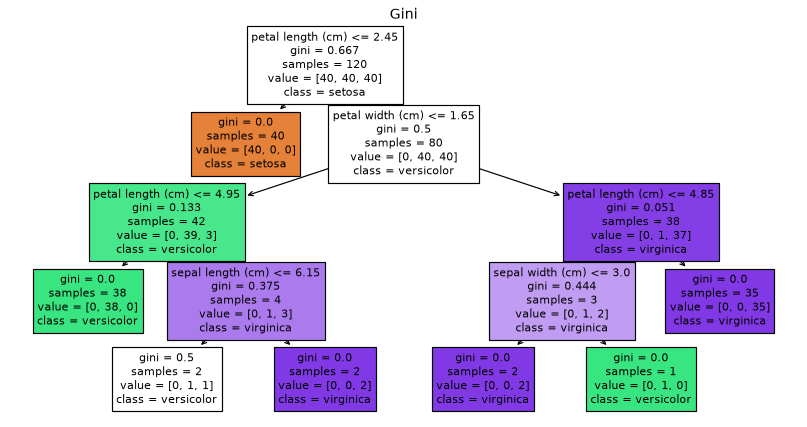

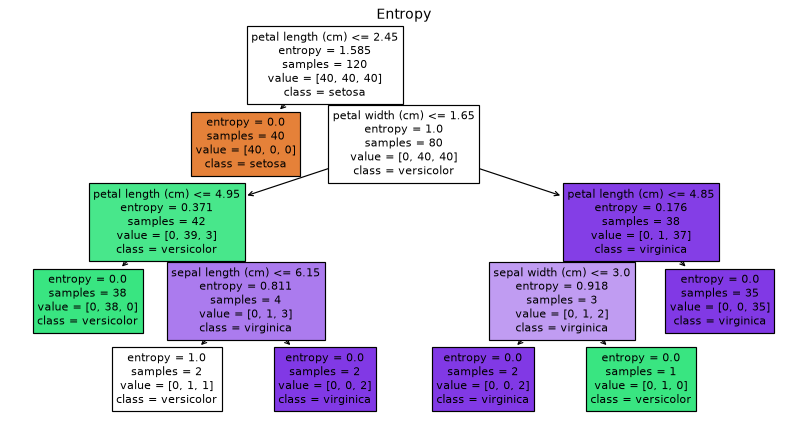

In [4]:
from sklearn.metrics import precision_recall_fscore_support
results=[]
for name,model in models.items():
    prediction=model.predict(X_test)
    print("\nModel:",name)
    print(confusion_matrix(y_test,prediction))
    print(classification_report(y_test,prediction,zero_division=0))
    precision,recall,f1,_=precision_recall_fscore_support(y_test,prediction,average="weighted",zero_division=0)
    results.append({"Model":name,"Accuracy":accuracy_score(y_test,prediction),"Precision":precision,"Recall":recall,"F1":f1})
print(pd.DataFrame(results).to_string(index=False))

for name,model in models.items():
    print(name,"Depth:",model.get_depth(),"Leaves:",model.get_n_leaves())
    plt.figure(figsize=(12,6))
    plot_tree(model,feature_names=X.columns.tolist(),class_names=iris.target_names,filled=True)
    plt.title(name);plt.show()


## Task 5. Tune maximum depth and minimum samples per leaf using cross-validation.

This block implements the task above. Variables from earlier blocks are reused.


In [5]:
from sklearn.model_selection import GridSearchCV
for criterion in ["gini","entropy"]:
    search=GridSearchCV(DecisionTreeClassifier(criterion=criterion,random_state=42),
       {"max_depth":[2,3,5,None],"min_samples_leaf":[1,3,5]},cv=3,scoring="f1_weighted")
    search.fit(X_train,y_train)
    print(criterion,"Best settings:",search.best_params_,"Training CV F1:",search.best_score_)
    print(classification_report(y_test,search.predict(X_test),zero_division=0))


gini Best settings: {'max_depth': 3, 'min_samples_leaf': 3} Training CV F1: 0.9582341269841269
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

entropy Best settings: {'max_depth': 3, 'min_samples_leaf': 3} Training CV F1: 0.9499629629629629
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## Viva preparation guide



**1. What are X and y?**

X contains the predictor columns; y contains the target we want to predict. X is a 2D table and y is a 1D series.

**2. Why split training and testing data?**

Fit using the training examples. Evaluate on separate examples to estimate how well the model generalizes.

**3. What do fit() and predict() mean?**

fit() learns parameters from training examples. predict() applies the learned model to new feature rows.

**4. Why random_state=42?**

It makes random splits or model choices reproducible. The number 42 has no special mathematical meaning.

**5. What is data leakage?**

Information unavailable for a real prediction accidentally influences training. Examples: including the answer in X or fitting a scaler on test data. Fit learned preprocessing only on training data.

**6. What is overfitting?**

The model learns training-specific details/noise and does worse on unseen data. Control complexity and use validation or cross-validation.

**7. What is a hyperparameter?**

A setting chosen outside model fitting, such as max_depth, K or the number of trees. Choose it using training validation, not by repeatedly optimizing the final test result.

**8. How do I fix FileNotFoundError or KeyError?**

Open Jupyter in the praceice folder, keep data/ beside this notebook, and print df.columns.tolist() to check exact column names. Do not change X and y row counts separately.

**9. What does the confusion matrix contain?**

Rows are actual classes and columns are predicted classes, in the printed label order. For binary labels [0,1], it is [[TN,FP],[FN,TP]].

**10. Define accuracy, precision, recall and F1.**

Accuracy=(TP+TN)/N. Precision=TP/(TP+FP). Recall=TP/(TP+FN). F1=2PR/(P+R). classification_report prints per-class values and macro/weighted averages. zero_division=0 handles an undefined score.

**11. Why can accuracy be misleading?**

If most examples belong to one class, always predicting that class may give high accuracy. Inspect minority-class recall, precision, F1 and the confusion matrix.

**12. Why stratify=y?**

It approximately preserves class proportions in training and test splits. Each class needs enough examples.

**13. How does a decision tree work?**

It asks feature-threshold questions, sending records down branches until a leaf predicts a class.

**14. Gini impurity?**

Gini=1-sum(p_i^2). It is zero for a pure node. A split is chosen to reduce weighted child impurity.

**15. Entropy?**

Entropy=-sum(p_i*log2(p_i)), with zero-probability terms treated as zero. Information gain is parent entropy minus weighted child entropy.

**16. Why limit max_depth?**

Very deep trees can memorize noise. Limiting depth often reduces overfitting and makes the plotted tree easier to explain.

**17. Does a tree need scaling?**

Usually no. It compares thresholds; it does not calculate Euclidean distances.

**18. What are leaves and feature importance?**

Leaves hold final class decisions. Impurity-based feature importance measures accumulated split improvements; it is not causation and can be biased.

**19. Complexity?**

For a reasonably balanced tree, training is often roughly O(p*n*log n), depending on implementation; prediction follows one path of length equal to tree depth. Deep worst cases can cost more.

**20. What does GridSearchCV do?**

It fits each parameter combination on training folds, scores validation folds and refits the best setting on the complete training split.

**21. What is min_samples_leaf?**

The minimum number of training examples required in a leaf. Larger values usually smooth decisions and reduce complexity.

**22. Why a common split?**

Different test rows could change scores independently of the splitting criterion, making the comparison unfair.

**23. Which criterion always wins?**

Neither. Gini and entropy can produce similar or different trees; conclusions must follow the observed scores, structure and validation uncertainty.


### Task-to-code map

- **Block 1:** Load a suitable classification dataset.
- **Block 2:** Prepare the data and use a fixed train-test split.
- **Block 3:** Train one Decision Tree using Gini impurity and another using entropy.
- **Block 4:** Compare the tree structures and test-set performance.
- **Block 5:** Tune maximum depth and minimum samples per leaf using cross-validation.
